# Tutorial 4: The `PowerCurve` Object

LayOWt provides the `PowerCurve` object to store wind turbine power and thrust curves, as well as many other attributes.
This object has many useful methods to load wind tubrine power curve data from common formats such as DTU´s WAsP .wtg files
and other common text formats such as .csv and .txt files.

Power curve data can also be loaded directly from OW´s corporate power curve database.

## 1. Creating a `PowerCurve` Object
### 1.1. Creating a `PowerCurve` Object Manually

A `PowerCurve` instance can be created manually by passing it a set of parameters. The full list of parameters that the class accepts is shown below:

1. **wind_speed**: wind speed bins in m/s.
2. **power**: Active power in kW for each wind_speed bin.
3. **ct**: Thrust coefficient for each wind_speed bin.
4. **rotor_diameter**: Rotor diameter in m.
5. **hub_height**: Hub height in m.
6. **air_density**: Air density for which the power curve is defined in kg/m3.
7. **cut_in**: Cut-in wind speed in m/s. If it is not provided, it is derived from the input wind speed and power data.
8. **rated_ws**: Rated wind speed in m/s. If it is not provided, it is derived from the input wind speed and power data.
9. **cut_out**: Cut-out wind speed in m/s. If it is not provided, it is derived from the input wind speed and power data.
10. **curve_id**: Id of the power curve for traceability purposes.
11. **manufacturer**: Manufacturer of the power curve for traceability purposes.

Only the `wind_speed`, `power`, and `ct` parameters are mandatory, the rest are optional.

Lets say we had loaded wind speed, powr and thrust coefficient data loaded and wanted to create a `PowerCurve` from this data.

In [1]:
# imports
from layowt.wtg import PowerCurve
import pandas as pd

In [2]:
# creating data from a .txt file
power_curve_df = pd.read_csv("tutorial_inputs/example_power_curve.txt", sep="\t", header=None, names=("wind_speed", "power", "ct"))
power_curve_df

,wind_speed,power,ct
0,0.0,0,0.0
1,0.5,0,0.0
2,1.0,0,0.0
3,1.5,0,0.0
4,2.0,0,0.0
...,...,...,...
64,32.0,0,0.0
65,32.5,0,0.0
66,33.0,0,0.0
67,33.5,0,0.0


In [3]:
# Creating a PowerCurve
pc = PowerCurve(wind_speed=power_curve_df["wind_speed"], power=power_curve_df["power"], ct=power_curve_df["ct"])
pc

Now that the `PowerCurve` is created, we can access all of its information through the following two attributes:

1. data: this attribute holds all of the power and thrust performance. A `pandas.DataFrame` with wind speed bins as index and 'power' and 'ct' columns.
2. attributes: a dictionary with all of the information about the `PowerCurve`.

Let's check them out.

In [4]:
pc.data

,power,ct
wind_speed,,
0.0,0,0.0
0.5,0,0.0
1.0,0,0.0
1.5,0,0.0
2.0,0,0.0
...,...,...
32.0,0,0.0
32.5,0,0.0
33.0,0,0.0


In [5]:
pc.attributes

{'rotor_diameter': None,
 'rated_power': 20000,
 'hub_height': None,
 'air_density': None,
 'cut_in': 3.0,
 'rated_ws': 13.5,
 'cut_out': 30.0,
 'curve_id': None,
 'manufacturer': None,
 'curve_date': datetime.date(2022, 8, 22),
 'ref_document_id': 'Unknown',
 'revision': 0,
 'curve_type': None}

As you can see from the `PowerCurve` attributes, some of them have been filled in automatically. The initialisation method derives
attributes such as rated power, cut-in, rated, and cut-out wind speeds, the curve_date without us having to explicitly pass them as parameters.

### 1.2. Creating a `PowerCurve` Object from OW's Database

Probably a more useful way of creating `PowerCurve` objects, is to fetch the data directly from OW's internal power curve database.
This can be accomplished by using the `from_database` class method. This mathod takes a curve_id which references a unique power curve from the
OW database, and returns a `PowerCurve` from that data.

.. tip:: When fetching data for many power curves from the database, it is more efficient to pass a database engine connection to the `from_database`
 class method. If an engine is not passed, it is implicitly created by `from_database` for each database call.

.. note:: When establishing the first connection to the database, a popup window will appear asking the user to authenticate to the database using OW's
active directory credentials.

In [6]:
engine = PowerCurve.database_engine()
with engine.connect() as conn:
    pc_database = PowerCurve.from_database("DD-222_14700_MWW_1.230_0.06_004", engine=conn)
pc_database.attributes

{'rotor_diameter': 236.0,
 'rated_power': 14700.0,
 'hub_height': None,
 'air_density': 1.23,
 'cut_in': 3.0,
 'rated_ws': 14.0,
 'cut_out': 32.0,
 'curve_id': 'DD-222_14700_MWW_1.230_0.06_004',
 'manufacturer': 'SGRE',
 'curve_date': datetime.date(2022, 4, 10),
 'ref_document_id': 'SGRE-OF-PPM-40-0000-L310-00',
 'revision': 4,
 'curve_type': 'Commercial'}

We can also plot the `PowerCurve` using the `plot` convenience method to check that everything has loaded correctly.

(<Figure size 576x432 with 2 Axes>,
 <AxesSubplot:title={'center':'Power Curve: DD-222_14700_MWW_1.230_0.06_004'}, xlabel='Wind Speed [m/s]', ylabel='Active Power [kW]'>)

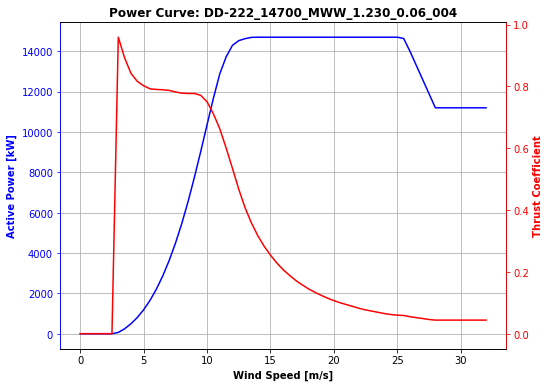

In [7]:
pc_database.plot()

### 1.3. Creating a `PowerCurve` Object from a DTU WAsP .wtg File

We can also load .wtg files directly into a `PowerCurve` using the `from_wtg` class method.

(<Figure size 576x432 with 2 Axes>,
 <AxesSubplot:title={'center':'Power Curve: DD-222_14700_MWW_1.230_0.06_004'}, xlabel='Wind Speed [m/s]', ylabel='Active Power [kW]'>)

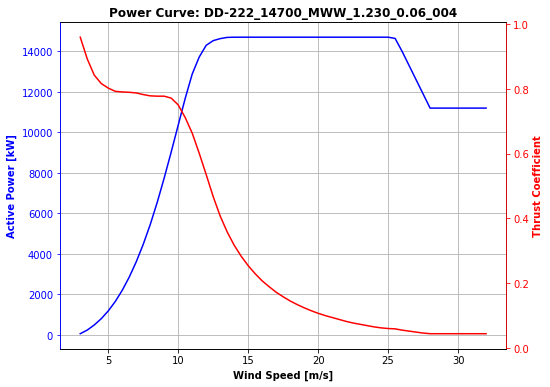

In [8]:
pc_wtg = PowerCurve.from_wtg("tutorial_inputs/example_wtg.wtg")
pc_wtg.plot()

### 1.4. Creating a `PowerCurve` Object from a text file File

We can also load text files (.csv, .txt, etc.) directly into a `PowerCurve` using the `from_text` class method.

(<Figure size 576x432 with 2 Axes>,
 <AxesSubplot:title={'center':'Power Curve: None'}, xlabel='Wind Speed [m/s]', ylabel='Active Power [kW]'>)

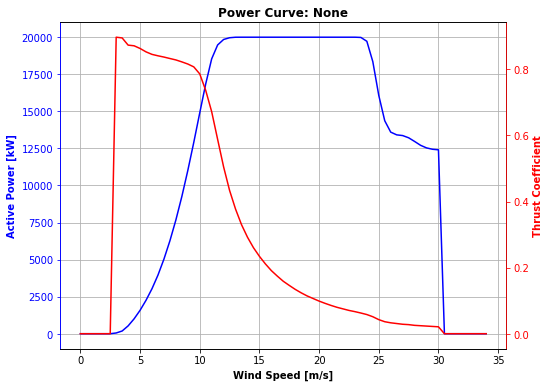

In [9]:
pc_text = PowerCurve.from_text("tutorial_inputs/example_power_curve.txt", pc_cols=(0, 1, 2), sep="\t", header=None)
pc_text.plot()

## 2. Interpolating a `PowerCurve`

A common task with power curves, is to interpolate them into smaller wind speed bins than those reported by the manufacturer.
This can be accomplished easily with the `interpolate` method. This method acts on a `PowerCurve` instance and only requires
the wind speed bin step as an input. A copy of the of the original `PowerCurve` is returned with interpolated power and thrust curves.  

In [12]:
pc_interpolated = pc_database.interpolate(ws_step=0.1)
pc_interpolated.data.loc[5:6]

,power,ct
wind_speed,,
5.0,1188.000000,0.802000
5.1,1273.807554,0.799573
5.2,1363.272202,0.797120
5.3,1456.233072,0.794880
5.4,1552.529295,0.793093
5.5,1652.000000,0.792000
5.6,1755.090182,0.791408
5.7,1862.225361,0.790944
5.8,1973.215448,0.790576


(<Figure size 576x432 with 2 Axes>,
 <AxesSubplot:title={'center':'Power Curve: None'}, xlabel='Wind Speed [m/s]', ylabel='Active Power [kW]'>)

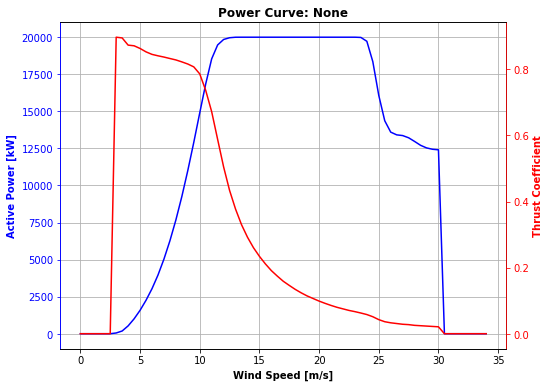

In [13]:
pc.plot()

## 3. Exporting a `PowerCurve`

A `PowerCurve` can be easily exported into text or .wtg formats.

### 3.1. Exporting to text

There is method bound to the `PowerCurve` class to export into a text file. This is because the power and thrust curve data is already in a pandas DataFrame,
which has its own method to export data to text files. Therefore it is recommended to use the `pandas.DataFrame.to_csv` method to accomplish this.

In [14]:
pc_interpolated.data.to_csv("pc_output.csv")

### 3.1. Exporting to .wtg

A `PowerCurve` can also be exported into .wtg format directly using the `to_wtg` method. Howerver, the .wtg format requires that a power curve has
a hub height defined. This can easily be done using the `set_hub_height` method prior to exporting. 

In [17]:
pc_interpolated.set_hub_height(150)
pc_interpolated.to_wtg("pc_output.wtg")

## 4. Database Queries

The `PowerCurve` class also comes equipped with various methods to query the database and return data that might be useful to filter power curves.

### 4.1. Listing All Commercial Turbines

We can fetch the data for all commercial turbines stored i nthe database using the `get_commerciak_turbines` class method. This returns a pandas DataFrame with
the turbine information.

In [2]:
commercial_turbines = PowerCurve.get_commercial_turbines()
commercial_turbines

,id,curve_id,model_name,manufacturer,project,revision,confidentiality,curve_date,ref_document_id,power_measurement_side,...,ti_min,ti_max,cut_in_ws,cut_out_ws,rated_ws,shear_min,shear_max,op_mode,high_wind_mode,general_comments
0,1,DD-222_14700_MWW_1.230_0.06_004,DD-222,SGRE,MWW,4,1,2022-04-10,SGRE-OF-PPM-40-0000-L310-00,LV,...,0.05,0.25,3.0,32.0,14.0,NaN,NaN,Normal,HWRT Rev0,None
1,2,MySE-260_16000_BAC_1.225_0.06_001,MySE-260,Mingyang,BAC,1,1,2022-05-17,M0C00016647,LV,...,NaN,NaN,3.0,25.0,12.0,NaN,NaN,Normal,None,None
2,3,V236_15000_BAC_1.100_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,13.0,0.0,0.30,Normal,None,None
3,4,V236_15000_BAC_1.125_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,13.0,0.0,0.30,Normal,None,None
4,5,V236_15000_BAC_1.150_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,12.5,0.0,0.30,Normal,None,None
5,6,V236_15000_BAC_1.175_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,12.5,0.0,0.30,Normal,None,None
6,7,V236_15000_BAC_1.200_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,12.5,0.0,0.30,Normal,None,None
7,8,V236_15000_BAC_1.225_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,12.5,0.0,0.30,Normal,None,None
8,9,V236_15000_BAC_1.250_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,12.5,0.0,0.30,Normal,None,None
9,10,V236_15000_BAC_1.275_0.06_001,V236,Vestas,BAC,1,1,2022-04-27,0104-2363v01,LV,...,0.04,0.12,3.0,31.0,12.0,0.0,0.30,Normal,None,None


We can then filter the DataFrame by whatever criteria we wish. For example, turbines who's manufacturer is not "Mingyang" and a rotor diameter larger than 240m.
We get 2 turbines satisfying this criteria.

In [27]:
filtered_turbines = commercial_turbines[(commercial_turbines["manufacturer"] != "Mingyang") & (commercial_turbines["rotor_diameter_m"] > 240)]
filtered_turbines

,id,curve_id,model_name,manufacturer,project,revision,confidentiality,curve_date,ref_document_id,power_measurement_side,...,ti_min,ti_max,cut_in_ws,cut_out_ws,rated_ws,shear_min,shear_max,op_mode,high_wind_mode,general_comments
12,13,Haliade-X-250_15000_MFW_1.225_0.06_004,Haliade-X-250,GE,MFW,4,1,2021-11-03,Doc-0084786,HV,...,NaN,NaN,3.5,28.0,13.0,0.0,0.12,Normal,None,None
13,18,DD-276_21000_MFW_1.225_0.06_000,DD-276,SGRE,MFW,0,3,2022-07-08,110000095695-00,LV,...,NaN,NaN,3.5,28.0,13.5,NaN,NaN,Normal,HWRT,None


### 4.2. Listing All Internal Turbines

.. warning:: Functionality pending

### 4.3. Comparing Curves from the Database

Another handy method lets us extract many power curcves from the database and also compare them by plotting their power and thrust curves.
This is done using the `compare_curves_from_database` class method.

We pass the `curve_id`'s of the curves we want to compare, and it returns a list of `PowerCurve` and a matplotlig figure and axes of power and thrust curve plots.

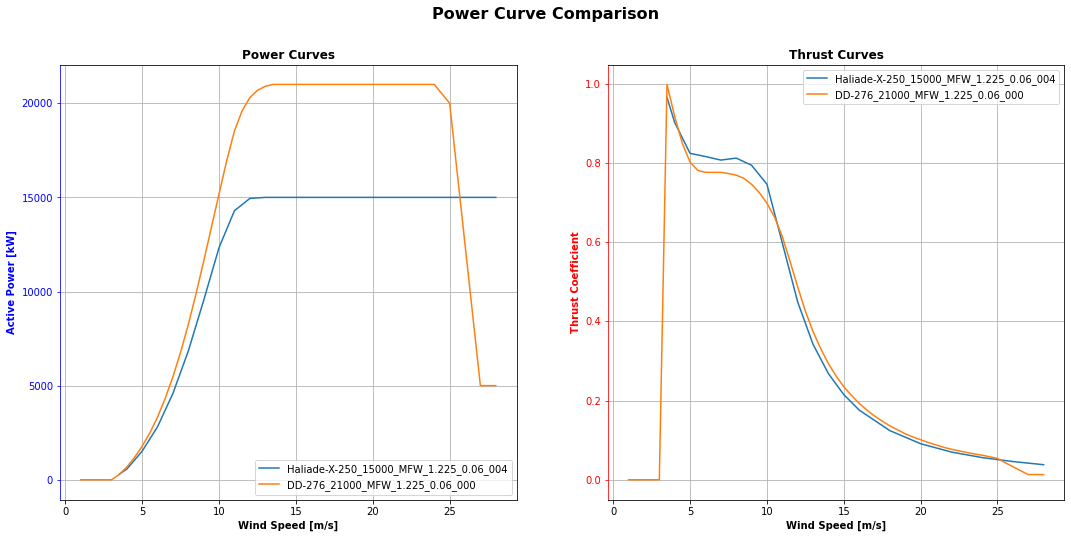

In [29]:
engine = PowerCurve.database_engine()
with engine.connect() as conn:
    power_curves, fig, axs = PowerCurve.compare_curves_from_database(filtered_turbines["curve_id"], engine=conn)

## 5. Calculating Gross Annual Energy Production

A `PowerCurve` can be used with `aep` functions to calculate annual energy productions.

## 5.1. Calculating Gross Annual Energy Production from a 2-parameter Weibull Distribution

We can use the `weibull_aep` function from the `aep` module to calculate GAEP.

In [9]:
from  layowt.aep import weibull_aep

power_curves = []

engine = PowerCurve.database_engine()
with engine.connect() as conn:
    for pc_id in commercial_turbines["curve_id"]:
        power_curves.append(PowerCurve.from_database(pc_id, engine=conn))

print(f"{'Curve ID:':<45} GAEP [GWh/y]")
for pc in power_curves:
    gaep = round(weibull_aep(pc, 11, 2.2, units="GWh", leap_year=True), 2)
    print(f"{pc.attributes['curve_id'] + ':':<45} {gaep:.2f}")

Curve ID:                                     GAEP [GWh/y]
DD-222_14700_MWW_1.230_0.06_004:              72.42
MySE-260_16000_BAC_1.225_0.06_001:            80.48
V236_15000_BAC_1.100_0.06_001:                74.56
V236_15000_BAC_1.125_0.06_001:                75.24
V236_15000_BAC_1.150_0.06_001:                75.91
V236_15000_BAC_1.175_0.06_001:                76.52
V236_15000_BAC_1.200_0.06_001:                77.13
V236_15000_BAC_1.225_0.06_001:                77.74
V236_15000_BAC_1.250_0.06_001:                78.32
V236_15000_BAC_1.275_0.06_001:                78.90
MySE-242_16000_HKW_1.225_0.06_001:            81.18
DD-236_15000_HKW_1.220_0.06_001:              75.66
Haliade-X-250_15000_MFW_1.225_0.06_004:       79.40
DD-276_21000_MFW_1.225_0.06_000:              104.66
V236_15000_KFW_1.100_0.06_000:                74.58
V236_15000_KFW_1.125_0.06_000:                75.19
V236_15000_KFW_1.150_0.06_000:                75.81
V236_15000_KFW_1.175_0.06_000:                76.39
V236